# Assignment 6 RNN Networks for Encoding and Decoding

Harrison Christophersen

Expected in `/content/drive/MyDrive/A6/`

- `eng-fra.txt`
- `cc.fr.300.vec.gz`
- `cc.en.300.vec.gz`

## 1. Setup

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Imports and device check.
import gzip, random, re, time, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("gpu:", torch.cuda.get_device_name(0))

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device: cuda
gpu: NVIDIA L4


In [3]:
# Paths and constants.
DATA = Path("/content/drive/MyDrive/A6")
CORPUS = DATA / "eng-fra.txt"
FR_VEC = DATA / "cc.fr.300.vec.gz"
EN_VEC = DATA / "cc.en.300.vec.gz"
OUT_CSV = DATA / "results.csv"

for p in (CORPUS, FR_VEC, EN_VEC):
    size = f"{p.stat().st_size / 1e9:.2f} GB" if p.exists() else "-"
    print(f"{'OK ' if p.exists() else 'MISSING'} {p.name:20s} {size}")

SOS_token, EOS_token = 0, 1
MAX_LENGTH = 10
BATCH_SIZE = 32
N_EPOCHS = 80

OK  eng-fra.txt          0.01 GB
OK  cc.fr.300.vec.gz     1.29 GB
OK  cc.en.300.vec.gz     1.33 GB


## 2. Loading data files

In [4]:
# Vocabulary bookkeeping: word index in both directions.
class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "SOS", 1: "EOS"}
        self.n_words = 2

    def addSentence(self, sentence):
        for word in sentence.split(" "):
            self.addWord(word)

    def addWord(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

In [5]:
# Turn Unicode to plain ASCII, lowercase, trim, and separate punctuation.
def unicodeToAscii(s):
    return "".join(c for c in unicodedata.normalize("NFD", s)
                   if unicodedata.category(c) != "Mn")

def normalizeString(s):
    s = unicodeToAscii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z!?]+", r" ", s)
    return s.strip()

In [6]:
# Split the file into lines, then into normalized pairs.
def readLangs(lang1, lang2, reverse=False):
    lines = open(CORPUS, encoding="utf-8").read().strip().split("\n")
    pairs = [[normalizeString(s) for s in l.split("\t")[:2]] for l in lines]
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang, output_lang = Lang(lang2), Lang(lang1)
    else:
        input_lang, output_lang = Lang(lang1), Lang(lang2)
    return input_lang, output_lang, pairs

In [7]:
# Trim to short, simple sentences and build both vocabularies.
eng_prefixes = ("i am ", "i m ", "he is", "he s ", "she is", "she s ",
                "you are", "you re ", "we are", "we re ", "they are", "they re ")

def filterPair(p):
    return (len(p[0].split(" ")) < MAX_LENGTH
            and len(p[1].split(" ")) < MAX_LENGTH
            and p[1].startswith(eng_prefixes))

def filterPairs(pairs):
    return [pair for pair in pairs if filterPair(pair)]

def prepareData(lang1, lang2, reverse=False):
    input_lang, output_lang, pairs = readLangs(lang1, lang2, reverse)
    print(f"Read {len(pairs)} sentence pairs")
    pairs = filterPairs(pairs)
    print(f"Trimmed to {len(pairs)} sentence pairs")
    for pair in pairs:
        input_lang.addSentence(pair[0])
        output_lang.addSentence(pair[1])
    print("Counted words:")
    print(f"  {input_lang.name}: {input_lang.n_words}")
    print(f"  {output_lang.name}: {output_lang.n_words}")
    return input_lang, output_lang, pairs

input_lang, output_lang, pairs = prepareData("eng", "fra", reverse=True)
print()
print(random.choice(pairs))

Read 135842 sentence pairs
Trimmed to 11445 sentence pairs
Counted words:
  fra: 4601
  eng: 2991

['nous craignons de manquer notre train', 'we re afraid we ll miss our train']


In [8]:
# Pad every sentence to MAX_LENGTH, append EOS, wrap in a DataLoader.
def indexesFromSentence(lang, sentence):
    return [lang.word2index[word] for word in sentence.split(" ")]

def tensorFromSentence(lang, sentence):
    indexes = indexesFromSentence(lang, sentence) + [EOS_token]
    return torch.tensor(indexes, dtype=torch.long, device=device).view(1, -1)

def get_dataloader(batch_size):
    n = len(pairs)
    input_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)
    target_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)
    for idx, (inp, tgt) in enumerate(pairs):
        inp_ids = indexesFromSentence(input_lang, inp) + [EOS_token]
        tgt_ids = indexesFromSentence(output_lang, tgt) + [EOS_token]
        input_ids[idx, :len(inp_ids)] = inp_ids
        target_ids[idx, :len(tgt_ids)] = tgt_ids
    data = TensorDataset(torch.LongTensor(input_ids).to(device),
                         torch.LongTensor(target_ids).to(device))
    return DataLoader(data, sampler=RandomSampler(data), batch_size=batch_size)

train_dataloader = get_dataloader(BATCH_SIZE)
print(f"{len(train_dataloader)} batches per epoch")

358 batches per epoch


## 3. Pretrained embeddings

FastText is used on both sides for consistency.

The `.vec.gz` files hold about 2M words each. They are streamed line by line and a
vector is kept only if the word is in our vocabulary, so nothing large is ever held in
memory. Words with no vector get a random init matched to the scale of the real ones;
`SOS` and `EOS` are always in that group.

In [9]:
# Stream a gzipped fastText .vec and keep only words we actually need.
def load_fasttext(path, lang, limit=2_000_000):
    wanted = set(lang.word2index)
    found = {}
    with gzip.open(path, "rt", encoding="utf-8", errors="ignore") as f:
        _n, dim = map(int, f.readline().split())
        for i, line in enumerate(f):
            if i >= limit or len(found) == len(wanted):
                break
            parts = line.rstrip().split(" ")
            if parts[0] in wanted:
                found[parts[0]] = np.asarray(parts[1:], dtype=np.float32)
    return found, dim


def build_matrix(lang, vectors, dim):
    rng = np.random.default_rng(SEED)
    scale = float(np.std(np.stack(list(vectors.values()))))
    matrix = rng.normal(0, scale, (lang.n_words, dim)).astype(np.float32)
    hits = 0
    for i in range(lang.n_words):
        word = lang.index2word[i]
        if word in vectors:
            matrix[i] = vectors[word]
            hits += 1
    print(f"  {lang.name}: {hits}/{lang.n_words} found ({hits/lang.n_words:.1%}), "
          f"{lang.n_words - hits} randomly initialized")
    return torch.from_numpy(matrix)

In [10]:
# Load both languages. Roughly two minutes.
t0 = time.time()
fr_vecs, EMB_DIM = load_fasttext(FR_VEC, input_lang)
en_vecs, _ = load_fasttext(EN_VEC, output_lang)
print(f"loaded in {time.time() - t0:.0f}s, dim = {EMB_DIM}\n")

print("OOV report:")
ENC_WEIGHTS = build_matrix(input_lang, fr_vecs, EMB_DIM)
DEC_WEIGHTS = build_matrix(output_lang, en_vecs, EMB_DIM)

loaded in 112s, dim = 300

OOV report:
  fra: 4351/4601 found (94.6%), 250 randomly initialized
  eng: 2986/2991 found (99.8%), 5 randomly initialized


In [11]:
# Which French words had no vector, and why.
missing = [input_lang.index2word[i] for i in range(2, input_lang.n_words)
           if input_lang.index2word[i] not in fr_vecs]
print(f"{len(missing)} French words missing. Sample:")
print(missing[:30])

248 French words missing. Sample:
['faineante', 'immunisee', 'alitee', 'reposee', 'ruinee', 'remuee', 'meticuleuse', 'affolee', 'pensionnee', 'gavee', 'sideree', 'schcoumoune', 'fortunee', 'enfoiree', 'fauchees', 'sauvees', 'desolees', 'coincees', 'fatiguees', 'givree', 'givrees', 'assuetude', 'clouee', 'ingenu', 'offensee', 'indignee', 'amendee', 'obstinee', 'affairee', 'chancarde']


## 4. The Seq2Seq Model

In [12]:
# Build an embedding (pretrained or random) plus a projection if the dims differ.
def make_embedding(n_words, hidden_size, pretrained, freeze):
    if pretrained is not None:
        emb = nn.Embedding.from_pretrained(pretrained.clone(), freeze=freeze)
        emb_dim = pretrained.size(1)
    else:
        emb = nn.Embedding(n_words, hidden_size)
        emb_dim = hidden_size
    proj = nn.Linear(emb_dim, hidden_size) if emb_dim != hidden_size else nn.Identity()
    return emb, proj

In [13]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers=1, dropout_p=0.1,
                 pretrained=None, freeze=False):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.embedding, self.project = make_embedding(
            input_size, hidden_size, pretrained, freeze)
        self.gru = nn.GRU(hidden_size, hidden_size, num_layers=num_layers,
                          batch_first=True, dropout=dropout_p if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        embedded = self.dropout(self.project(self.embedding(input)))
        output, hidden = self.gru(embedded)
        return output, hidden

In [14]:
class DecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, num_layers=1, dropout_p=0.1,
                 pretrained=None, freeze=False):
        super(DecoderRNN, self).__init__()
        self.embedding, self.project = make_embedding(
            output_size, hidden_size, pretrained, freeze)
        self.gru = nn.GRU(hidden_size, hidden_size, num_layers=num_layers,
                          batch_first=True, dropout=dropout_p if num_layers > 1 else 0.0)
        self.out = nn.Linear(hidden_size, output_size)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long,
                                    device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs = []

        for i in range(MAX_LENGTH):
            decoder_output, decoder_hidden = self.forward_step(
                decoder_input, decoder_hidden)
            decoder_outputs.append(decoder_output)

            if target_tensor is not None:
                decoder_input = target_tensor[:, i].unsqueeze(1)   # teacher forcing
            else:
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()

        decoder_outputs = F.log_softmax(torch.cat(decoder_outputs, dim=1), dim=-1)
        return decoder_outputs, decoder_hidden, None

    def forward_step(self, input, hidden):
        output = F.relu(self.project(self.embedding(input)))
        output, hidden = self.gru(output, hidden)
        return self.out(output), hidden

In [15]:
class BahdanauAttention(nn.Module):
    def __init__(self, hidden_size):
        super(BahdanauAttention, self).__init__()
        self.Wa = nn.Linear(hidden_size, hidden_size)
        self.Ua = nn.Linear(hidden_size, hidden_size)
        self.Va = nn.Linear(hidden_size, 1)

    def forward(self, query, keys):
        scores = self.Va(torch.tanh(self.Wa(query) + self.Ua(keys)))
        scores = scores.squeeze(2).unsqueeze(1)
        weights = F.softmax(scores, dim=-1)
        context = torch.bmm(weights, keys)
        return context, weights


class AttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, num_layers=1, dropout_p=0.1,
                 pretrained=None, freeze=False):
        super(AttnDecoderRNN, self).__init__()
        self.embedding, self.project = make_embedding(
            output_size, hidden_size, pretrained, freeze)
        self.attention = BahdanauAttention(hidden_size)
        self.gru = nn.GRU(2 * hidden_size, hidden_size, num_layers=num_layers,
                          batch_first=True, dropout=dropout_p if num_layers > 1 else 0.0)
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long,
                                    device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs, attentions = [], []

        for i in range(MAX_LENGTH):
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs)
            decoder_outputs.append(decoder_output)
            attentions.append(attn_weights)

            if target_tensor is not None:
                decoder_input = target_tensor[:, i].unsqueeze(1)   # teacher forcing
            else:
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()

        decoder_outputs = F.log_softmax(torch.cat(decoder_outputs, dim=1), dim=-1)
        return decoder_outputs, decoder_hidden, torch.cat(attentions, dim=1)

    def forward_step(self, input, hidden, encoder_outputs):
        embedded = self.dropout(self.project(self.embedding(input)))
        query = hidden[-1:].permute(1, 0, 2)      # top layer only; see change 3
        context, attn_weights = self.attention(query, encoder_outputs)
        input_gru = torch.cat((embedded, context), dim=2)
        output, hidden = self.gru(input_gru, hidden)
        return self.out(output), hidden, attn_weights

## 5. Training

In [16]:
# One epoch of teacher-forced training.
def train_epoch(dataloader, encoder, decoder, encoder_optimizer,
                decoder_optimizer, criterion):
    total_loss = 0
    for data in dataloader:
        input_tensor, target_tensor = data

        encoder_optimizer.zero_grad()
        decoder_optimizer.zero_grad()

        encoder_outputs, encoder_hidden = encoder(input_tensor)
        decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor)

        loss = criterion(decoder_outputs.view(-1, decoder_outputs.size(-1)),
                         target_tensor.view(-1))
        loss.backward()

        encoder_optimizer.step()
        decoder_optimizer.step()
        total_loss += loss.item()

    return total_loss / len(dataloader)

In [17]:
# Timing helpers from the tutorial.
import math

def asMinutes(s):
    m = math.floor(s / 60)
    return f"{m}m {s - m * 60:.0f}s"

def timeSince(since, percent):
    now = time.time()
    s = now - since
    es = s / percent
    return f"{asMinutes(s)} (- {asMinutes(es - s)})"


def train(train_dataloader, encoder, decoder, n_epochs, learning_rate=0.001,
          print_every=10):
    start = time.time()
    plot_losses = []
    encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
    criterion = nn.NLLLoss()

    for epoch in range(1, n_epochs + 1):
        loss = train_epoch(train_dataloader, encoder, decoder,
                           encoder_optimizer, decoder_optimizer, criterion)
        plot_losses.append(loss)
        if epoch % print_every == 0:
            print(f"  {timeSince(start, epoch / n_epochs)}  "
                  f"epoch {epoch}/{n_epochs}  loss {loss:.4f}")

    return plot_losses, time.time() - start

In [18]:
def showPlot(points, title=""):
    plt.figure(figsize=(7, 4))
    plt.plot(points)
    plt.xlabel("epoch"); plt.ylabel("NLL loss")
    if title:
        plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()

## 6. Evaluation

In [19]:
# Greedy decoding with no teacher forcing: the model reads its own predictions.
def evaluate(encoder, decoder, sentence):
    with torch.no_grad():
        input_tensor = tensorFromSentence(input_lang, sentence)
        encoder_outputs, encoder_hidden = encoder(input_tensor)
        decoder_outputs, _, decoder_attn = decoder(encoder_outputs, encoder_hidden)

        _, topi = decoder_outputs.topk(1)
        decoded_words = []
        for idx in topi.squeeze():
            if idx.item() == EOS_token:
                decoded_words.append("<EOS>")
                break
            decoded_words.append(output_lang.index2word[idx.item()])
    return decoded_words, decoder_attn


def evaluateRandomly(encoder, decoder, n=10):
    encoder.eval(); decoder.eval()
    for _ in range(n):
        pair = random.choice(pairs)
        output_words, _ = evaluate(encoder, decoder, pair[0])
        print(f">  {pair[0]}")
        print(f"=  {pair[1]}")
        print(f"<  {' '.join(output_words)}")
        print()


def exact_match(encoder, decoder, n=500):
    encoder.eval(); decoder.eval()
    sample = random.Random(SEED).sample(pairs, min(n, len(pairs)))
    hits = 0
    for src, tgt in sample:
        words, _ = evaluate(encoder, decoder, src)
        if " ".join(w for w in words if w != "<EOS>") == tgt:
            hits += 1
    return hits / len(sample)

## 7. Experiment harness

In [20]:
RESULTS = {}     # name -> result row
MODELS = {}      # name -> (encoder, decoder)
LOSSES = {}      # name -> per-epoch losses

def run_experiment(name, attention=True, pretrained=False, freeze=False,
                   num_layers=1, hidden_size=128, n_epochs=N_EPOCHS):
    print(f"=== {name} ===")
    torch.manual_seed(SEED)

    enc_w = ENC_WEIGHTS if pretrained else None
    dec_w = DEC_WEIGHTS if pretrained else None

    encoder = EncoderRNN(input_lang.n_words, hidden_size, num_layers=num_layers,
                         pretrained=enc_w, freeze=freeze).to(device)
    Decoder = AttnDecoderRNN if attention else DecoderRNN
    decoder = Decoder(hidden_size, output_lang.n_words, num_layers=num_layers,
                      pretrained=dec_w, freeze=freeze).to(device)

    n_params = (sum(p.numel() for p in encoder.parameters() if p.requires_grad)
                + sum(p.numel() for p in decoder.parameters() if p.requires_grad))
    print(f"  {n_params:,} trainable parameters")

    losses, elapsed = train(train_dataloader, encoder, decoder, n_epochs)
    acc = exact_match(encoder, decoder)

    RESULTS[name] = dict(
        name=name,
        attention=attention,
        embeddings=("fastText frozen" if pretrained and freeze
                    else "fastText tuned" if pretrained else "random"),
        layers=num_layers, hidden=hidden_size, params=n_params,
        train_sec=round(elapsed, 1), final_loss=round(losses[-1], 4),
        exact_match=round(acc, 3))
    MODELS[name] = (encoder, decoder)
    LOSSES[name] = losses

    pd.DataFrame([RESULTS[k] for k in sorted(RESULTS)]).to_csv(OUT_CSV, index=False)
    np.save(DATA / f"losses_{name[0]}.npy", np.array(losses))

    print(f"  done in {asMinutes(elapsed)} | loss {losses[-1]:.4f} | "
          f"exact match {acc:.1%}\n")
    return encoder, decoder, losses

## 8. Baseline and attention

Configuration 0 is the plain decoder of section 13.7, where the entire source sentence
must pass through one fixed-width context vector. Configuration 1 adds attention, which
lets the decoder read every encoder state (section 13.8).

In [21]:
enc0, dec0, loss0 = run_experiment("0: no attention, random emb",
                                   attention=False, pretrained=False)

=== 0: no attention, random emb ===
  1,555,759 trainable parameters
  0m 56s (- 6m 29s)  epoch 10/80  loss 0.8017
  1m 45s (- 5m 14s)  epoch 20/80  loss 0.4133
  2m 34s (- 4m 16s)  epoch 30/80  loss 0.2412
  3m 23s (- 3m 23s)  epoch 40/80  loss 0.1557
  4m 12s (- 2m 31s)  epoch 50/80  loss 0.1063
  5m 1s (- 1m 40s)  epoch 60/80  loss 0.0792
  5m 51s (- 0m 50s)  epoch 70/80  loss 0.0623
  6m 42s (- 0m 0s)  epoch 80/80  loss 0.0511
  done in 6m 42s | loss 0.0511 | exact match 24.2%



In [22]:
enc1, dec1, loss1 = run_experiment("1: attention, random emb",
                                   attention=True, pretrained=False)

=== 1: attention, random emb ===
  1,638,064 trainable parameters
  1m 35s (- 11m 5s)  epoch 10/80  loss 0.5098
  3m 11s (- 9m 33s)  epoch 20/80  loss 0.1561
  4m 46s (- 7m 56s)  epoch 30/80  loss 0.0742
  6m 20s (- 6m 20s)  epoch 40/80  loss 0.0477
  7m 55s (- 4m 45s)  epoch 50/80  loss 0.0386
  9m 29s (- 3m 10s)  epoch 60/80  loss 0.0335
  11m 3s (- 1m 35s)  epoch 70/80  loss 0.0303
  12m 36s (- 0m 0s)  epoch 80/80  loss 0.0297
  done in 12m 36s | loss 0.0297 | exact match 81.2%



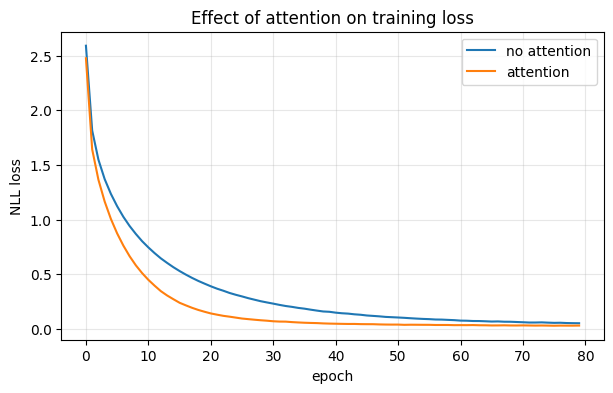

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(loss0, label="no attention")
plt.plot(loss1, label="attention")
plt.xlabel("epoch"); plt.ylabel("NLL loss"); plt.legend()
plt.title("Effect of attention on training loss")
plt.grid(alpha=0.3); plt.show()

In [24]:
evaluateRandomly(enc1, dec1)

>  je suis myope
=  i m nearsighted
<  i m nearsighted <EOS>

>  ils sont vieux
=  they re old
<  they re old <EOS>

>  nous sommes toutes differentes
=  we re all different
<  we re all different <EOS>

>  vous etes sur la liste
=  you re on the list
<  you re on the list the list <EOS>

>  je saigne gravement
=  i m bleeding badly
<  i m bleeding badly lazy <EOS>

>  il n est pas parfait
=  he isn t perfect
<  he isn t perfect <EOS>

>  tu es egoiste
=  you re selfish
<  you re selfish <EOS>

>  aujourd hui elle va beaucoup mieux qu hier
=  she s much better today than yesterday
<  she s much better today than yesterday <EOS>

>  ils courent dans le parc
=  they are running in the park
<  they are running in the park <EOS>

>  je ne suis pas normal
=  i m not normal
<  i m not normal <EOS>



## 9. Pretrained embeddings

Frozen keeps fastText's general-purpose
semantics intact but leaves the model only the projection layer to adapt with;
fine-tuning lets the vectors specialize to this task.

In [25]:
enc2, dec2, loss2 = run_experiment("2: attention, fastText frozen",
                                   pretrained=True, freeze=True)

=== 2: attention, fastText frozen ===
  743,344 trainable parameters
  1m 38s (- 11m 28s)  epoch 10/80  loss 0.8424
  3m 16s (- 9m 48s)  epoch 20/80  loss 0.3681
  4m 54s (- 8m 10s)  epoch 30/80  loss 0.1937
  6m 33s (- 6m 33s)  epoch 40/80  loss 0.1180
  8m 11s (- 4m 55s)  epoch 50/80  loss 0.0794
  9m 49s (- 3m 16s)  epoch 60/80  loss 0.0615
  11m 27s (- 1m 38s)  epoch 70/80  loss 0.0536
  13m 5s (- 0m 0s)  epoch 80/80  loss 0.0435
  done in 13m 5s | loss 0.0435 | exact match 25.2%



In [26]:
enc3, dec3, loss3 = run_experiment("3: attention, fastText tuned",
                                   pretrained=True, freeze=False)

=== 3: attention, fastText tuned ===
  3,020,944 trainable parameters
  1m 43s (- 11m 58s)  epoch 10/80  loss 0.6457
  3m 25s (- 10m 14s)  epoch 20/80  loss 0.2188
  5m 8s (- 8m 33s)  epoch 30/80  loss 0.1014
  6m 51s (- 6m 51s)  epoch 40/80  loss 0.0605
  8m 35s (- 5m 9s)  epoch 50/80  loss 0.0436
  10m 19s (- 3m 26s)  epoch 60/80  loss 0.0420
  12m 2s (- 1m 43s)  epoch 70/80  loss 0.0379
  13m 46s (- 0m 0s)  epoch 80/80  loss 0.0309
  done in 13m 46s | loss 0.0309 | exact match 83.4%



## 10. Capacity experiments

Three configurations: more layers, more hidden units, then both. One variable changes
at a time so the comparison stays interpretable.

In [27]:
enc4, dec4, loss4 = run_experiment("4: 2 layers, 128 hidden",
                                   pretrained=True, num_layers=2, hidden_size=128)

=== 4: 2 layers, 128 hidden ===
  3,219,088 trainable parameters
  1m 58s (- 13m 43s)  epoch 10/80  loss 0.8915
  3m 56s (- 11m 47s)  epoch 20/80  loss 0.3913
  5m 55s (- 9m 51s)  epoch 30/80  loss 0.1949
  7m 52s (- 7m 52s)  epoch 40/80  loss 0.1129
  9m 50s (- 5m 54s)  epoch 50/80  loss 0.0801
  11m 47s (- 3m 56s)  epoch 60/80  loss 0.0654
  13m 44s (- 1m 58s)  epoch 70/80  loss 0.0578
  15m 42s (- 0m 0s)  epoch 80/80  loss 0.0521
  done in 15m 42s | loss 0.0521 | exact match 36.0%



In [28]:
enc5, dec5, loss5 = run_experiment("5: 1 layer, 256 hidden",
                                   pretrained=True, num_layers=1, hidden_size=256)

=== 5: 1 layer, 256 hidden ===
  4,318,352 trainable parameters
  1m 47s (- 12m 32s)  epoch 10/80  loss 0.2496
  3m 34s (- 10m 43s)  epoch 20/80  loss 0.0667
  5m 22s (- 8m 56s)  epoch 30/80  loss 0.0448
  7m 9s (- 7m 9s)  epoch 40/80  loss 0.0417
  8m 56s (- 5m 21s)  epoch 50/80  loss 0.0378
  10m 43s (- 3m 34s)  epoch 60/80  loss 0.0367
  12m 30s (- 1m 47s)  epoch 70/80  loss 0.0322
  14m 18s (- 0m 0s)  epoch 80/80  loss 0.0357
  done in 14m 18s | loss 0.0357 | exact match 75.8%



In [29]:
enc6, dec6, loss6 = run_experiment("6: 2 layers, 256 hidden",
                                   pretrained=True, num_layers=2, hidden_size=256)

=== 6: 2 layers, 256 hidden ===
  5,107,856 trainable parameters
  2m 3s (- 14m 23s)  epoch 10/80  loss 0.5114
  4m 8s (- 12m 23s)  epoch 20/80  loss 0.1267
  6m 11s (- 10m 19s)  epoch 30/80  loss 0.0666
  8m 15s (- 8m 15s)  epoch 40/80  loss 0.0536
  10m 18s (- 6m 11s)  epoch 50/80  loss 0.0469
  12m 21s (- 4m 7s)  epoch 60/80  loss 0.0473
  14m 25s (- 2m 4s)  epoch 70/80  loss 0.0454
  16m 29s (- 0m 0s)  epoch 80/80  loss 0.0433
  done in 16m 29s | loss 0.0433 | exact match 33.6%



## 11. Results

In [30]:
df = pd.DataFrame([RESULTS[k] for k in sorted(RESULTS)]).reset_index(drop=True)
df

,name,attention,embeddings,layers,hidden,params,train_sec,final_loss,exact_match
0,"0: no attention, random emb",False,random,1,128,1555759,401.7,0.0511,0.242
1,"1: attention, random emb",True,random,1,128,1638064,756.2,0.0297,0.812
2,"2: attention, fastText frozen",True,fastText frozen,1,128,743344,785.1,0.0435,0.252
3,"3: attention, fastText tuned",True,fastText tuned,1,128,3020944,825.7,0.0309,0.834
4,"4: 2 layers, 128 hidden",True,fastText tuned,2,128,3219088,942.1,0.0521,0.360
5,"5: 1 layer, 256 hidden",True,fastText tuned,1,256,4318352,857.6,0.0357,0.758
6,"6: 2 layers, 256 hidden",True,fastText tuned,2,256,5107856,989.0,0.0433,0.336


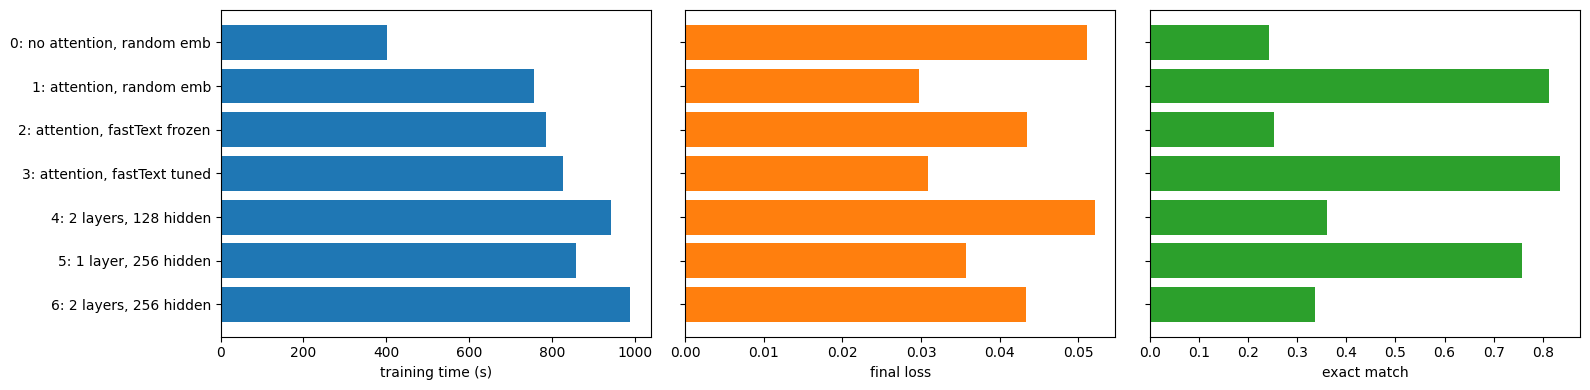

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].barh(df["name"], df["train_sec"]);   axes[0].set_xlabel("training time (s)")
axes[1].barh(df["name"], df["final_loss"], color="tab:orange")
axes[1].set_xlabel("final loss")
axes[2].barh(df["name"], df["exact_match"], color="tab:green")
axes[2].set_xlabel("exact match")
for ax in axes:
    ax.invert_yaxis()
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
plt.tight_layout(); plt.show()

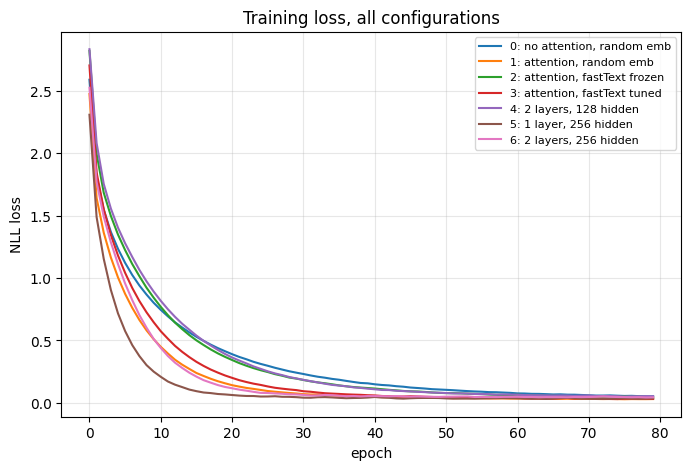

In [32]:
# Loss curves for every configuration.
plt.figure(figsize=(8, 5))
for name in sorted(LOSSES):
    plt.plot(LOSSES[name], label=name)
plt.xlabel("epoch"); plt.ylabel("NLL loss")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.title("Training loss, all configurations")
plt.show()

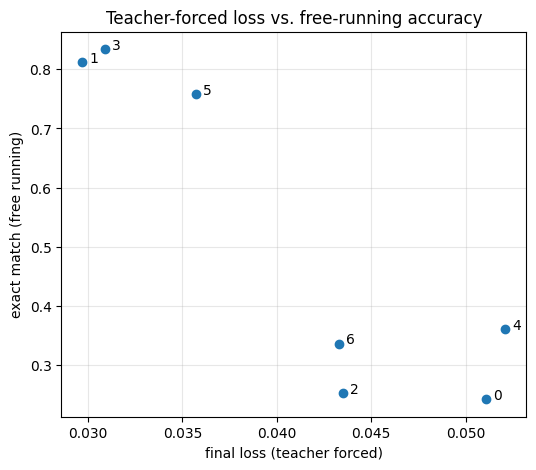

In [33]:
# Does lower loss actually mean better translations?
plt.figure(figsize=(6, 5))
plt.scatter(df["final_loss"], df["exact_match"])
for _, r in df.iterrows():
    plt.annotate(r["name"][0], (r["final_loss"], r["exact_match"]),
                 xytext=(5, 0), textcoords="offset points")
plt.xlabel("final loss (teacher forced)"); plt.ylabel("exact match (free running)")
plt.title("Teacher-forced loss vs. free-running accuracy")
plt.grid(alpha=0.3); plt.show()

## 12. Visualizing attention

In [34]:
def showAttention(input_sentence, output_words, attentions):
    fig, ax = plt.subplots(figsize=(6, 5))
    cax = ax.matshow(attentions.cpu().numpy(), cmap="bone")
    fig.colorbar(cax)
    ax.set_xticks(range(len(input_sentence.split(" ")) + 1))
    ax.set_yticks(range(len(output_words)))
    ax.set_xticklabels(input_sentence.split(" ") + ["<EOS>"], rotation=90)
    ax.set_yticklabels(output_words)
    plt.tight_layout(); plt.show()


def evaluateAndShowAttention(encoder, decoder, input_sentence):
    output_words, attentions = evaluate(encoder, decoder, input_sentence)
    print(f"input  = {input_sentence}")
    print(f"output = {' '.join(output_words)}")
    showAttention(input_sentence, output_words,
                  attentions[0, :len(output_words),
                             :len(input_sentence.split(" ")) + 1])

best configuration: 3: attention, fastText tuned (83.4% exact match)

input  = il n est pas aussi grand que son pere
output = he is not as tall as his father <EOS>


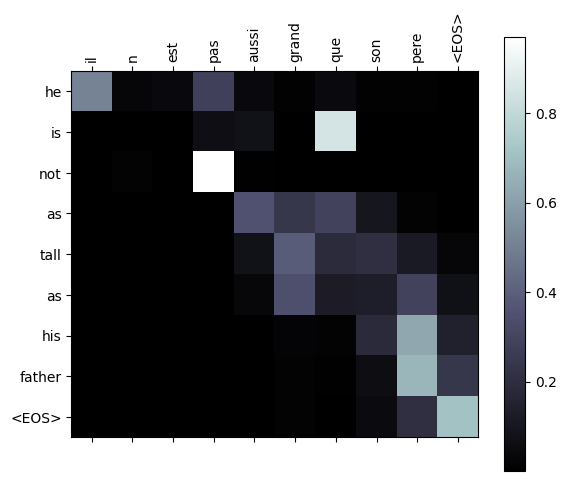

input  = je suis trop fatigue pour conduire
output = i m too tired to drive <EOS>


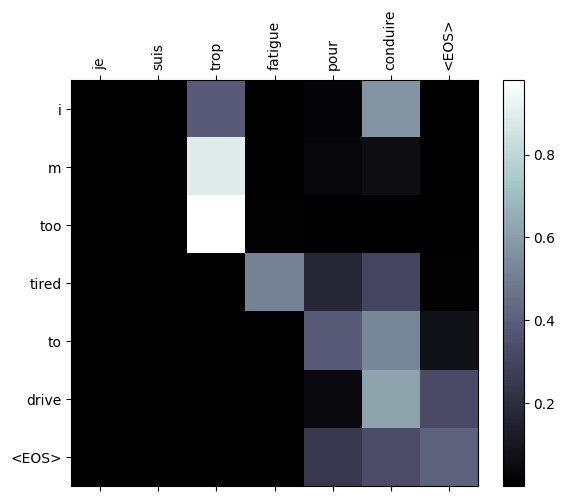

input  = je suis desole si c est une question idiote
output = i m sorry if this is a stupid question <EOS>


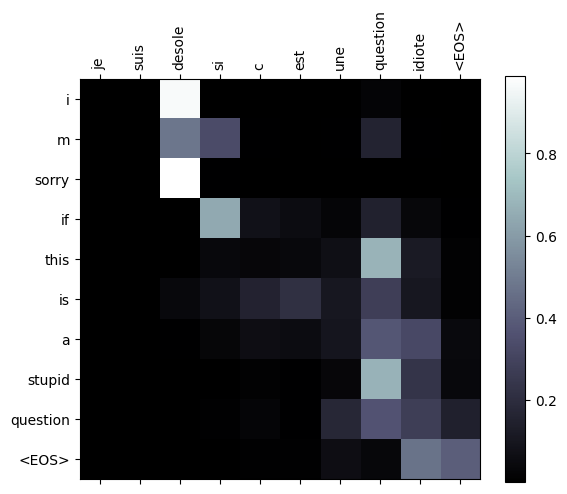

input  = je suis reellement fiere de vous
output = i m really proud of you are <EOS>


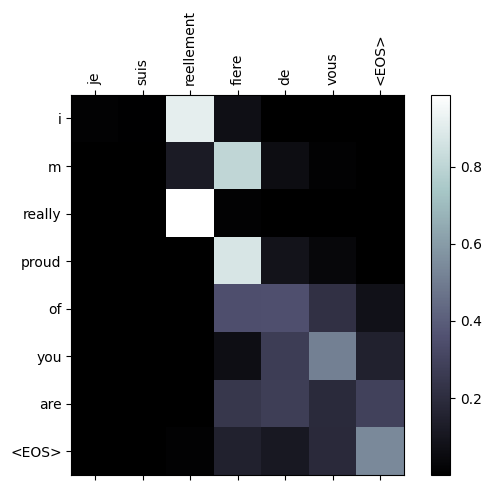

In [35]:
# Use whichever configuration scored best, chosen automatically.
best_name = max(RESULTS, key=lambda k: RESULTS[k]["exact_match"])
print(f"best configuration: {best_name} "
      f"({RESULTS[best_name]['exact_match']:.1%} exact match)\n")
best_enc, best_dec = MODELS[best_name]

for s in ["il n est pas aussi grand que son pere",
          "je suis trop fatigue pour conduire",
          "je suis desole si c est une question idiote",
          "je suis reellement fiere de vous"]:
    evaluateAndShowAttention(best_enc, best_dec, s)

## 13. Discussion

Attention was definetly the largest factor, exact match went from 24.2% to 81.2% with only 5% more parameters, training time nearly doubled though which is the real trade off. Pretrained fastText helped when fine-tuned (83.4%) but collapsed to 25.2% when frozen. Adding capacity hurt in all three experiments: more hidden units cost the least (75.8%) and more layers the most (36.0% and 33.6%), every experiment took longer to train than the baseline. The final loss also tracked exact match poorly, a loss gap of 0.008 separated the 75-83% group from the 24-36% group. This is because the loss is measured under teacher forcing while exact match decodes free-running where one early error derails the rest of the sentence.